# Training a VQE with analytic gradients

A variational quantum eigensolver (VQE) tunes the angles of a circuit to minimize the energy of a Hamiltonian, and it needs the gradient of that energy at every step. On a quantum computer the gradient comes from the parameter-shift rule: two extra circuits per parameter. An `HSMPO` can do much better, because it knows the state classically: `HSMPO.gradient` computes every derivative at once, for about the cost of two expectation values.

In this tutorial you will learn how to call `gradient`, check it against the parameter-shift rule, train a VQE with it, and see how its cost scales with the system size.

In [1]:
import time
import sys

import matplotlib.pyplot as plt
import numpy as np
from qibo.config import log

from mpstab import HSMPO
from mpstab.models.ansatze import HardwareEfficient
sys.path.append("../..")  # examples/, home of the plot style
from plotting import COLORS, set_style

set_style()
log.setLevel("WARNING")  # silence qibo's backend message

## The problem

We look for the ground state of the transverse-field Ising model on a ring of $n$ qubits,

$$H = -\sum_{i=1}^{n} Z_i Z_{i+1} - h \sum_{i=1}^{n} X_i, \qquad Z_{n+1} \equiv Z_1,$$

at the critical field $h = 1$. We write it as a dict of Pauli strings, one of the observable formats `HSMPO` accepts.

This model maps to free fermions, so its ground energy is known exactly for any $n$:

$$E_0 = -\sum_{m=0}^{n-1} \sqrt{1 + h^2 - 2h\cos k_m}, \qquad k_m = \frac{(2m+1)\pi}{n}.$$

This gives us an exact reference even for sizes where exact diagonalization is out of reach.

In [2]:
def tfim_ring(nqubits, field=1.0):
    terms = {}
    for q in range(nqubits):
        zz = ["I"] * nqubits
        zz[q] = zz[(q + 1) % nqubits] = "Z"
        terms["".join(zz)] = -1.0
        x = ["I"] * nqubits
        x[q] = "X"
        terms["".join(x)] = -field
    return terms


def ground_energy(nqubits, field=1.0):
    k = np.pi * (2 * np.arange(nqubits) + 1) / nqubits
    return -np.sum(np.sqrt(1 + field**2 - 2 * field * np.cos(k)))

## The ansatz

We use `HardwareEfficient`: each layer applies an $R_Y$ rotation to every qubit, then a ring of CZ gates. With 4 layers on 10 qubits it has 40 parameters, all of them $R_Y$ angles, so it prepares real states, which is enough for this Hamiltonian. The angles start at random values.

The CZ gates are Clifford, so `HSMPO` absorbs them into its stabilizer tableau; every $R_Y$ becomes a Pauli rotation applied to the MPS.

In [3]:
n = 10
hamiltonian = tfim_ring(n)
exact = ground_energy(n)

np.random.seed(0)
hsmpo = HSMPO(HardwareEfficient(nqubits=n, nlayers=4), progress=False)
initial = np.array([p[0] for p in hsmpo.get_parameters()])
print(f"{len(initial)} parameters")
print(f"initial energy: {hsmpo.expectation(hamiltonian):.4f}   exact: {exact:.4f}")

40 parameters
initial energy: -0.3518   exact: -12.7849


## The gradient

`gradient` takes the same observable as `expectation` and returns one derivative per parameter, in the order of `get_parameters`. Its options are:

| Option | Default | Meaning |
|---|---|---|
| `parameters` | all | indices of the parameters to differentiate |
| `light_cone` | `True` | skip the rotations that cannot affect the observable (exact) |
| `method` | `"adjoint"` | `"adjoint"`: one backward pass, about twice the cost of `expectation`; `"flips"`: one partial circuit per parameter, slower but with nothing extra to truncate |
| `costate_bond` | `2 * max_bond_dimension` | bond cap of the backward pass; `max_bond_dimension` is about twice as fast, for twice the error |
| `groups` | `1` | split the observable's terms into this many blocks of neighbouring terms, each differentiated on its own, narrower light cone, in parallel processes |
| `n_workers` | `min(groups, cpu_count)` | processes for the blocks; the pool starts on the first call and is reused |
| `return_value` | `False` | also return the energy, which the gradient's forward pass computes anyway |

As a reference we implement the parameter-shift rule: shift one angle by $\pm\pi/2$, evaluate the energy on both shifted circuits, and take half the difference. Each evaluation uses `expectation_from_partition`, which also skips the rotations outside the observable's light cone.

In [4]:
def parameter_shift(hsmpo, hamiltonian, parameters, indices=None):
    indices = range(len(parameters)) if indices is None else indices
    gradient = []
    for i in indices:
        values = []
        for sign in (1, -1):
            shifted = parameters.copy()
            shifted[i] += sign * np.pi / 2
            hsmpo.ansatz.circuit.set_parameters(shifted)
            values.append(hsmpo.expectation_from_partition(hamiltonian, 0.0)[0])
        gradient.append((values[0] - values[1]) / 2)
    hsmpo.ansatz.circuit.set_parameters(parameters)
    return np.array(gradient)


start = time.perf_counter()
analytic = hsmpo.gradient(hamiltonian)
analytic_time = time.perf_counter() - start

start = time.perf_counter()
shifted = parameter_shift(hsmpo, hamiltonian, initial)
shift_time = time.perf_counter() - start

print(f"max |difference|: {np.abs(analytic - shifted).max():.1e}")
print(f"analytic: {analytic_time:.3f} s   parameter shift: {shift_time:.3f} s")

max |difference|: 5.6e-07
analytic: 0.047 s   parameter shift: 0.556 s


The two gradients agree to the truncation cutoff of the MPS, and the analytic one is already several times faster on this small circuit.

## Training

mpstab only provides the gradient; any optimizer can use it. Here we minimize the energy with Adam, a standard gradient-based optimizer, written out in a few lines. Each step sets the new angles with `set_parameters` and asks for the energy and the gradient together, with `return_value=True`: the analytic gradient computes the energy in its forward pass anyway. `set_parameters` only rebuilds the `HSMPO`'s cached state when something reads it, such as `expectation`, so the analytic loop never pays for it. We run the same training twice, from the same initial angles: once with the analytic gradient and once with the parameter-shift rule.

In [5]:
class Adam:
    def __init__(self, learning_rate=0.05, beta1=0.9, beta2=0.999, eps=1e-8):
        self.learning_rate, self.beta1, self.beta2, self.eps = learning_rate, beta1, beta2, eps
        self.m = self.v = 0.0
        self.t = 0

    def step(self, parameters, gradient):
        self.t += 1
        self.m = self.beta1 * self.m + (1 - self.beta1) * gradient
        self.v = self.beta2 * self.v + (1 - self.beta2) * gradient**2
        m = self.m / (1 - self.beta1**self.t)
        v = self.v / (1 - self.beta2**self.t)
        return parameters - self.learning_rate * m / (np.sqrt(v) + self.eps)


def train(hsmpo, parameters, energy_and_gradient, steps):
    optimizer = Adam()
    energies, times = [], []
    start = time.perf_counter()
    for step in range(steps):
        hsmpo.set_parameters(parameters)
        energy, gradient = energy_and_gradient(parameters)
        energies.append(energy)
        times.append(time.perf_counter() - start)
        parameters = optimizer.step(parameters, gradient)
    return np.array(energies), np.array(times)


def shift_rule_step(parameters):
    return hsmpo.expectation(hamiltonian), parameter_shift(hsmpo, hamiltonian, parameters)


steps = 200
runs = {
    "analytic": train(
        hsmpo, initial, lambda p: hsmpo.gradient(hamiltonian, return_value=True), steps
    ),
    "parameter shift": train(hsmpo, initial, shift_rule_step, steps),
}
for name, (energies, times) in runs.items():
    print(
        f"{name:>15}: {times[-1]:6.1f} s, {times[-1] / steps * 1e3:4.0f} ms per step, "
        f"final energy {energies[-1]:.6f}"
    )

       analytic:    4.3 s,   21 ms per step, final energy -12.647731
parameter shift:  105.6 s,  528 ms per step, final energy -12.647731


The two runs follow the same trajectory: the gradients agree, so Adam takes the same steps. The parameter-shift line is dashed so that both stay visible. Against the wall time, the analytic gradient reaches the same energy many times sooner.

The error does not go to zero: four layers of $R_Y$ rotations cannot represent the ground state exactly, so the training stops at the best state this ansatz can reach.

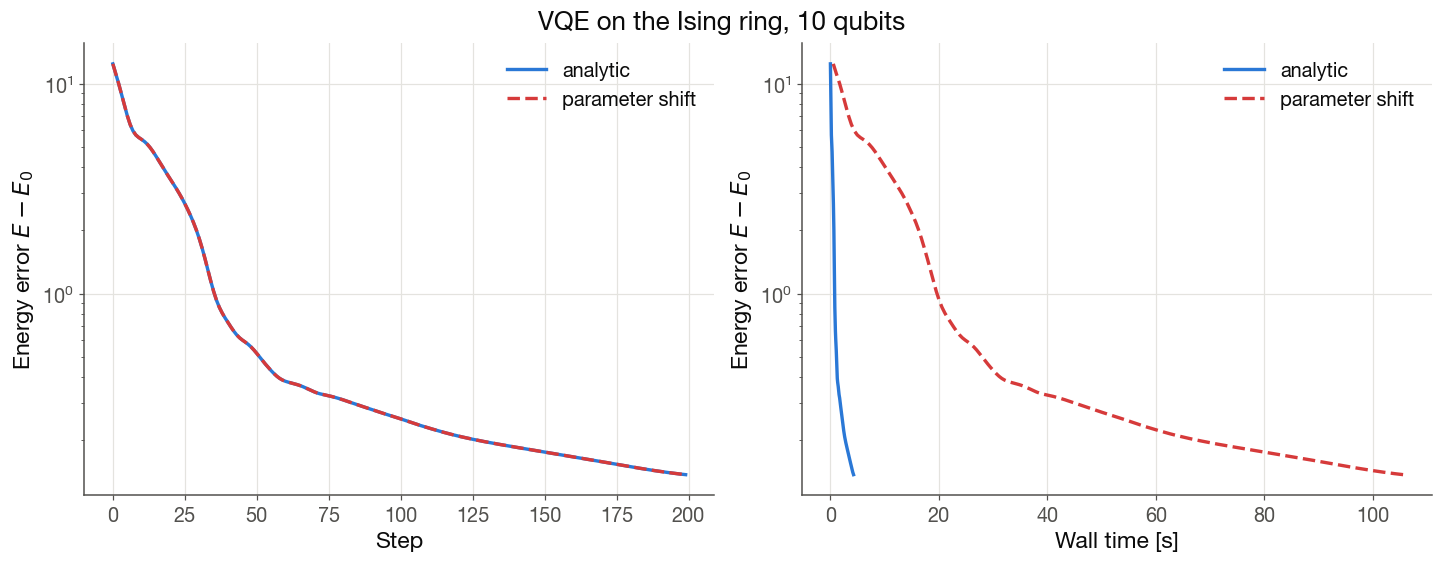

In [6]:
styles = {
    "analytic": dict(color=COLORS["blue"]),
    "parameter shift": dict(color=COLORS["red"], ls="--"),
}
fig, (left, right) = plt.subplots(1, 2, figsize=(13, 5))
for name, (energies, times) in runs.items():
    left.semilogy(energies - exact, label=name, **styles[name])
    right.semilogy(times, energies - exact, label=name, **styles[name])
left.set_xlabel("Step")
right.set_xlabel("Wall time [s]")
for axis in (left, right):
    axis.set_ylabel("Energy error $E - E_0$")
    axis.legend()
fig.suptitle(f"VQE on the Ising ring, {n} qubits")
plt.show()

## Cost per gradient

The parameter-shift rule needs two energy evaluations per parameter, so its cost grows with the number of parameters times the cost of one evaluation. The analytic gradient costs about one forward and one backward pass of the circuit, whatever the number of parameters.

We time one gradient for growing rings, with 4 layers and a bond dimension capped at $\chi = 32$. To keep this quick, the parameter-shift rule is timed on 16 evenly spaced parameters and scaled to all of them.

In [7]:
sizes = [10, 20, 40, 60]
max_bond = 32
cost = {"analytic": [], "parameter shift": []}
for size in sizes:
    np.random.seed(0)
    model = HSMPO(
        HardwareEfficient(nqubits=size, nlayers=4), max_bond_dimension=max_bond, progress=False
    )
    observable = tfim_ring(size)
    parameters = np.array([p[0] for p in model.get_parameters()])

    start = time.perf_counter()
    model.gradient(observable)
    cost["analytic"].append(time.perf_counter() - start)

    subset = np.linspace(0, len(parameters) - 1, 16).astype(int)
    start = time.perf_counter()
    parameter_shift(model, observable, parameters, subset)
    cost["parameter shift"].append(
        (time.perf_counter() - start) * len(parameters) / len(subset)
    )
    print(
        f"n = {size:2d}, {len(parameters):3d} parameters:  "
        f"analytic {cost['analytic'][-1]:6.2f} s   "
        f"parameter shift {cost['parameter shift'][-1]:7.2f} s   "
        f"({cost['parameter shift'][-1] / cost['analytic'][-1]:.0f}x)"
    )

n = 10,  40 parameters:  analytic   0.02 s   parameter shift    0.53 s   (25x)


n = 20,  80 parameters:  analytic   0.34 s   parameter shift    5.19 s   (15x)


n = 40, 160 parameters:  analytic   1.16 s   parameter shift   29.84 s   (26x)


n = 60, 240 parameters:  analytic   2.03 s   parameter shift   66.51 s   (33x)


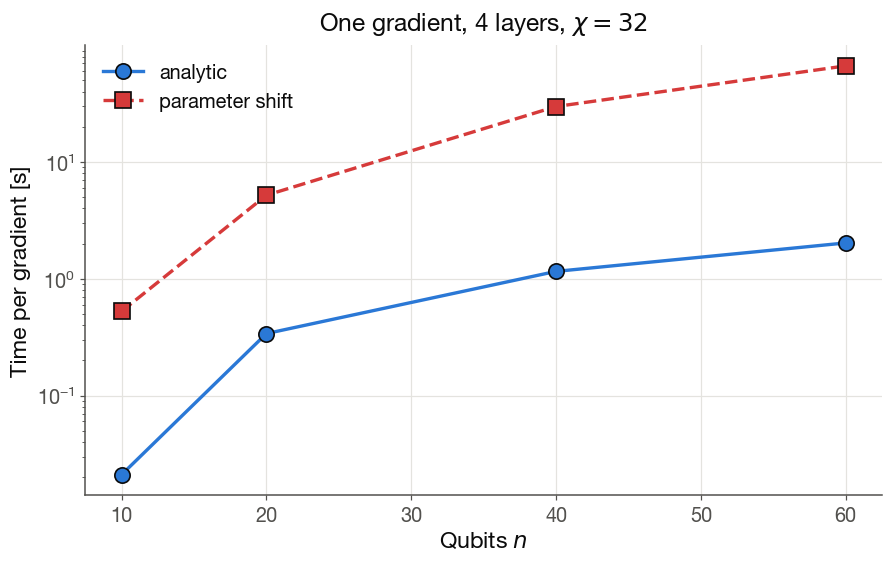

In [8]:
plt.semilogy(sizes, cost["analytic"], marker="o", label="analytic", **styles["analytic"])
plt.semilogy(
    sizes, cost["parameter shift"], marker="s", label="parameter shift", **styles["parameter shift"]
)
plt.xlabel("Qubits $n$")
plt.ylabel("Time per gradient [s]")
plt.title(f"One gradient, 4 layers, $\\chi = {max_bond}$")
plt.legend()
plt.show()

The gap widens with the size: at 60 qubits the circuit has 240 parameters, and the parameter-shift rule pays for 480 evaluations where the analytic gradient pays for about two.

## Larger systems

With the analytic gradient, training rings of tens of qubits takes well under a minute. We train 20, 40 and 60 qubits with the same ansatz, $\chi = 32$, and compare with the exact free-fermion energy through the relative error $(E - E_0)/|E_0|$.

Each term of $H$ only sees the rotations in its own light cone, which for 4 layers covers a few neighbouring qubits. With `groups=8` the terms are split into 8 blocks of neighbours, each differentiated on its own cone in a separate process: narrower cones carry less entanglement, so each block is cheaper, and at the same $\chi$ more accurate, than the whole Hamiltonian at once. The sum over blocks is exact.

In [9]:
large = {}
for size in [20, 40, 60]:
    np.random.seed(0)
    model = HSMPO(
        HardwareEfficient(nqubits=size, nlayers=4), max_bond_dimension=max_bond, progress=False
    )
    observable = tfim_ring(size)
    parameters = np.array([p[0] for p in model.get_parameters()])
    energies, times = train(
        model,
        parameters,
        lambda p: model.gradient(observable, groups=8, return_value=True),
        steps,
    )
    large[size] = (energies, times)
    error = (energies[-1] - ground_energy(size)) / abs(ground_energy(size))
    print(
        f"n = {size}: {times[-1]:5.0f} s ({times[-1] / steps:.2f} s per step), "
        f"E = {energies[-1]:.4f}, E0 = {ground_energy(size):.4f}, relative error {error:.1e}"
    )

n = 20:    14 s (0.07 s per step), E = -24.5519, E0 = -25.4910, relative error 3.7e-02


n = 40:    20 s (0.10 s per step), E = -49.7205, E0 = -50.9427, relative error 2.4e-02


n = 60:    36 s (0.18 s per step), E = -74.9931, E0 = -76.4031, relative error 1.8e-02


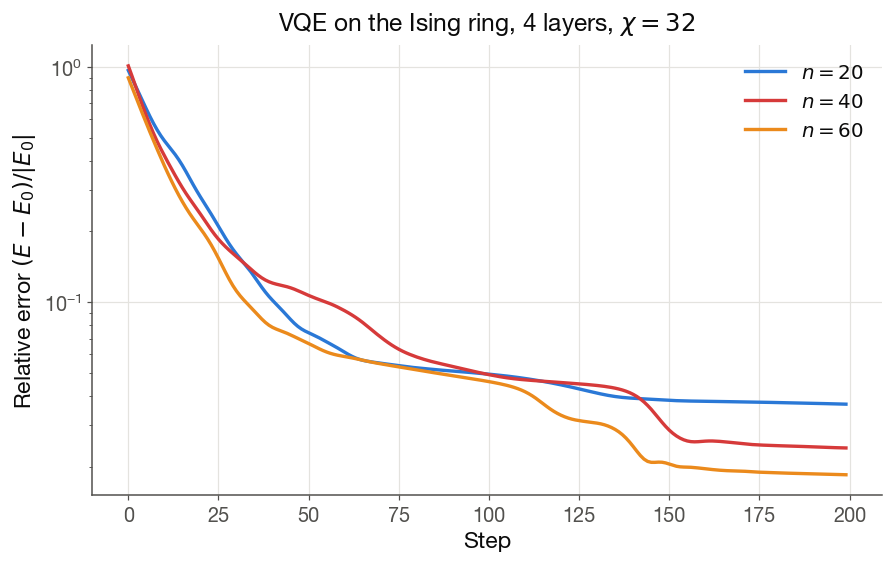

In [10]:
colors = [COLORS["blue"], COLORS["red"], COLORS["orange"]]
for (size, (energies, _)), color in zip(large.items(), colors):
    exact_size = ground_energy(size)
    plt.semilogy((energies - exact_size) / abs(exact_size), color=color, label=f"$n = {size}$")
plt.xlabel("Step")
plt.ylabel("Relative error $(E - E_0)/|E_0|$")
plt.title(f"VQE on the Ising ring, 4 layers, $\\chi = {max_bond}$")
plt.legend()
plt.show()

All three sizes train in a few hundred steps to a relative error of a few percent, set again by the four-layer ansatz rather than by the gradient. With the parameter-shift rule, each of these trainings would take tens of times longer.

## Summary

- `HSMPO.gradient(observable)` returns the derivative of `expectation(observable)` with respect to every parameter, matching the parameter-shift rule.
- mpstab provides the gradient, not an optimizer: `gradient(observable, return_value=True)` gives the energy and the gradient in one pass, for Adam, L-BFGS or any other method.
- `groups=k` differentiates blocks of neighbouring terms on their own light cones, in parallel processes: faster, and more accurate at the same $\chi$, while the cones are narrower than the circuit.
- The default `"adjoint"` method costs about two expectation values whatever the number of parameters, so it gets faster than the parameter-shift rule the larger the circuit.
- With a bond-dimension cap, the gradient inherits the truncation error of the MPS, to first order: an energy, and so the parameter-shift rule, is only affected to second order, so at the same $\chi$ the parameter-shift gradient looks more accurate. Raise $\chi$ when the gradient error matters; `costate_bond` controls the extra error of the backward pass.
- A parameter whose gate sits at a Clifford angle (a multiple of $\pi/2$) is absorbed into the stabilizer tableau and cannot be differentiated: `gradient` raises an error rather than returning zero.